# Banda simple con la banda siempre encendida: emisor por tandas de tres cajas para OpenPLC

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nebisman/deslab-py3/blob/main/notebooks/factory_io/LCS_banda_simple_emisor_tres_cajas_openplc.ipynb)

La escena es `banda_simple.factoryio`, en la carpeta `Factory scenes`: un **emisor** deja cajas al
comienzo de una banda de rodillos; la banda las lleva hasta una rampa que termina en un removedor.
Dos sensores retrorreflectivos vigilan la banda: `SensorInicio`, bajo el emisor, y `SensorFin`,
antes de la rampa.

En este modelo la **banda está siempre encendida** y el supervisor solo controla el emisor, que
trabaja **por tandas de tres cajas**. El emisor funciona al inicio y se apaga cuando la tercera caja
termina de pasar `SensorInicio`. Vuelve a emitir **solo cuando las tres cajas salieron** por
`SensorFin`, y se apaga otra vez con la tercera caja de la tanda siguiente. Así nunca hay más de
tres cajas en la banda. Nada arranca hasta que se pulsa el botón `BotonStart`.

El notebook
[`LCS_banda_simple_emisor_openplc`](LCS_banda_simple_emisor_openplc.ipynb) resuelve la misma
escena con una sola caja en la banda a la vez, y
[`LCS_banda_simple_openplc`](LCS_banda_simple_openplc.ipynb) con un supervisor que además apaga y
enciende la banda.

In [77]:
#@title Instalación de DESlab desde GitHub (solo en Colab; ejecute esta celda primero)
import importlib, shutil, subprocess, sys

if "google.colab" in sys.modules:
    if shutil.which("dot") is None:
        subprocess.run("apt-get -qq install -y graphviz > /dev/null", shell=True)
    %pip install -q networkx graphviz
    %pip install -q --force-reinstall --no-deps --no-cache-dir git+https://github.com/nebisman/deslab-py3.git
    importlib.invalidate_caches()
    for name in [m for m in sys.modules if m == "deslab" or m.startswith("deslab.")]:
        del sys.modules[name]
else:
    print("Fuera de Colab se usa el DESlab instalado en el entorno")

Fuera de Colab se usa el DESlab instalado en el entorno


In [78]:
from deslab import *

## 1. Señales de la escena y eventos

Los sensores son retrorreflectivos: valen 1 cuando el haz llega al reflector, es decir, cuando
**no** hay caja, y 0 cuando la caja corta el haz. Cuando la caja llega a un sensor, la señal pasa de
alto a bajo (**flanco de bajada**); cuando termina de pasar, de bajo a alto (**flanco de subida**).

| Evento | Significado | Señal | Tipo |
|---|---|---|---|
| `Emisor-ON`, `Emisor-OFF` | encender y apagar el emisor | `Emisor` (Coil 1) | controlable |
| `Caja-inicio` | una caja que sacó el emisor termina de pasar `SensorInicio` | flanco de subida de `SensorInicio` (Input 0) | no controlable |
| `Caja-sale` | la caja termina de pasar `SensorFin` y baja por la rampa | flanco de subida de `SensorFin` (Input 1) | no controlable |
| `start` | se pulsa el botón de arranque | `BotonStart` en 1 (Input 2) | no controlable |

La banda no tiene eventos: después del pulsador, el programa la deja encendida en cada scan
(secciones 5 y 6).

## 2. Planta

La planta tiene tres componentes:

* `Emisor`: apagado (0) o encendido (1).
* `Caja`: cuántas cajas hay en la banda, de 0 a 3. Cada `Caja-inicio` suma una caja y cada
  `Caja-sale` resta una. Como la banda siempre está encendida, toda caja que entra termina saliendo.
* `Boton`: el pulsador `BotonStart`, con dos estados. En el 0 solo puede ocurrir `start`; en el 1
  ocurren todos los demás eventos, con autolazos. Así, hasta que se pulsa el botón no se enciende el
  emisor ni entra o sale ninguna caja, y no hace falta una especificación de arranque. `start`
  ocurre una sola vez: después, el programa ignora el botón.

Con el emisor encendido durante tres cajas puede haber varias en la banda a la vez: la segunda caja
pasa `SensorInicio` antes de que la primera llegue a `SensorFin`. Por eso `Caja` cuenta las cajas en
lugar de alternar entre "sin caja" y "con caja". Con el modelo de una sola caja, el programa ignoraría
el segundo `Caja-inicio` seguido y perdería la cuenta. Basta contar hasta 3 porque el emisor saca a lo
sumo tres cajas por tanda y no saca más hasta que salen.

Después del pulsador, la planta no relaciona los sensores con el emisor: para ella, `Caja-inicio`
puede ocurrir aunque el emisor esté apagado. Las especificaciones tienen que tenerlo en cuenta (sección 3).

estados de la planta: 9


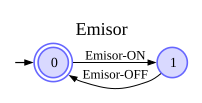

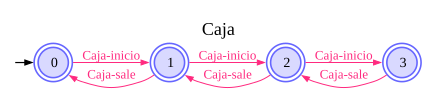

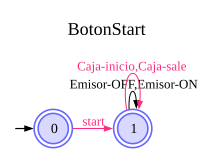

In [79]:
Emisor = fsa([0, 1], ['Emisor-ON', 'Emisor-OFF'],
             [(0, 'Emisor-ON', 1), (1, 'Emisor-OFF', 0)],
             [0], [0], Sigcon=['Emisor-ON', 'Emisor-OFF'], name='Emisor')
# el estado es el número de cajas en la banda
Caja = fsa([0, 1, 2, 3], ['Caja-inicio', 'Caja-sale'],
           [(0, 'Caja-inicio', 1), (1, 'Caja-inicio', 2), (2, 'Caja-inicio', 3),
            (1, 'Caja-sale', 0), (2, 'Caja-sale', 1), (3, 'Caja-sale', 2)],
           [0], [0, 1, 2, 3], Sigcon=set(), name='Caja')

# pulsador de arranque: antes de start no ocurre ningún otro evento
Boton = fsa([0, 1], ['start', 'Emisor-ON', 'Emisor-OFF', 'Caja-inicio', 'Caja-sale'],
            [(0, 'start', 1),
             # después de start, todos los demás eventos
             (1, 'Emisor-ON', 1), (1, 'Emisor-OFF', 1), (1, 'Caja-inicio', 1), (1, 'Caja-sale', 1)],
            [0], [0, 1], Sigcon=['Emisor-ON', 'Emisor-OFF'], name='BotonStart')

G = Emisor // Caja // Boton
print('estados de la planta:', len(G.X))
draw(Emisor, Caja, Boton)

## 3. Especificaciones

| Especificación | Qué pide |
|---|---|
| `ESP_tres_cajas` | después de encenderse, el emisor sigue encendido mientras pasan tres cajas por `SensorInicio` (tres `Caja-inicio`) y luego se apaga |
| `ESP_nueva_tanda` | el emisor se enciende al inicio y, después, solo cuando salieron por `SensorFin` las tres cajas de la tanda anterior (tres `Caja-sale`) |

`ESP_tres_cajas` cuenta las cajas que entran y no deja apagar el emisor antes de la tercera.
`ESP_nueva_tanda` cuenta las que salen desde que el emisor se encendió, así que no importa si alguna
sale mientras el emisor sigue encendido: el emisor vuelve a encenderse cuando salieron las tres.

**Autolazos.** Como la planta puede generar `Caja-inicio` y `Caja-sale` aunque el emisor esté
apagado, cada especificación lleva un autolazo de esos eventos en los estados donde no los
restringe. Sin autolazos, la especificación prohibiría un evento no controlable que la planta
puede generar; la síntesis tendría que evitar ese estado y, como no puede impedir el evento,
quitaría estados hasta el inicial, y el supervisor quedaría vacío.

| Especificación | Estado | Autolazos |
|---|---|---|
| `ESP_tres_cajas` | 0: emisor apagado | `Caja-inicio` |
| | 4: hay que apagar el emisor | `Caja-inicio` |
| `ESP_nueva_tanda` | 0: puede encender el emisor | `Caja-sale` |

Cada especificación solo lleva autolazos de los eventos de su alfabeto: `Caja-sale` queda libre
en `ESP_tres_cajas` y `Caja-inicio` en `ESP_nueva_tanda`.

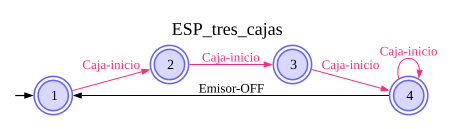

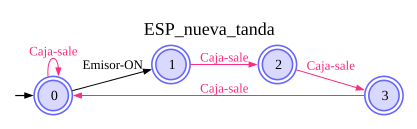

In [80]:
# el emisor saca tres cajas y se apaga
ESP_tres_cajas = fsa([1, 2, 3, 4], [ 'Emisor-OFF', 'Caja-inicio'],
                     [ (1, 'Caja-inicio', 2), (2, 'Caja-inicio', 3),
                      (3, 'Caja-inicio', 4), (4, 'Emisor-OFF', 1),
                      # autolazos
                     (4, 'Caja-inicio', 4)],
                     [1], [1, 2, 3, 4], Sigcon=['Emisor-ON', 'Emisor-OFF'], name='ESP_tres_cajas')
# el emisor se vuelve a encender cuando salieron las tres cajas
ESP_nueva_tanda = fsa([0, 1, 2, 3], ['Emisor-ON', 'Caja-sale'],
                      [(0, 'Emisor-ON', 1), (1, 'Caja-sale', 2), (2, 'Caja-sale', 3),
                       (3, 'Caja-sale', 0),
                       # autolazo
                       (0, 'Caja-sale', 0)],
                      [0], [0,1, 2, 3], Sigcon=['Emisor-ON'], name='ESP_nueva_tanda')

draw(ESP_tres_cajas, ESP_nueva_tanda)

## 4. Síntesis del supervisor

El supervisor es `supcontrollable(H, G)` con $H = G \parallel$ `ESP_tres_cajas` $\parallel$
`ESP_nueva_tanda`. Se comprueba que es controlable y no bloqueante.

estados de H: 109  estados del supervisor: 109
controlable: True
no bloqueante: True


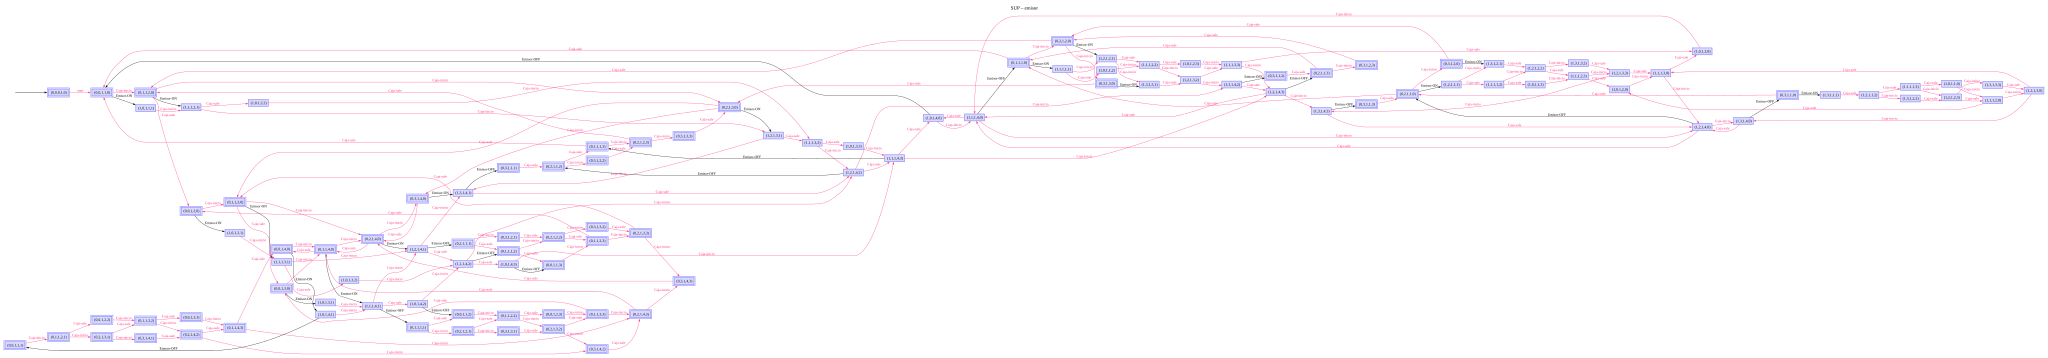

In [81]:
H = G //ESP_tres_cajas // ESP_nueva_tanda
SUP = supcontrollable(H, G).setpar(name='$SUP$ -- emisor', style='rectangle')
print('estados de H:', len(H.X), ' estados del supervisor:', len(SUP.X))
print('controlable:', iscontrollable(SUP, G))
print('no bloqueante:', coac(SUP).X == SUP.X)
SUP

## 5. Mapa de señales

Las direcciones son las de un dispositivo esclavo Modbus en OpenPLC: las entradas discretas de
Factory I/O (Inputs) llegan a `%IX100.x` y las bobinas (Coils) salen por `%QX100.x`.

| Señal de Factory I/O | Modbus | OpenPLC | Variable |
|---|---|---|---|
| `SensorInicio` | Input 0 | `%IX100.0` | `SensorInicio` |
| `SensorFin` | Input 1 | `%IX100.1` | `SensorFin` |
| `BotonStart` | Input 2 | `%IX100.2` | `BotonStart` |
| `Banda` | Coil 0 | `%QX100.0` | `Banda` |
| `Emisor` | Coil 1 | `%QX100.1` | `Emisor` |
| `Remover 0 (Remove)` | Coil 2 | `%QX100.2` | `Remover` |

`RE_INICIO` y `RE_SALE` son los flancos de subida de `SensorInicio` y `SensorFin` (bloques
`R_TRIG` en el programa): la caja termina de pasar el sensor. `start` es el nivel alto de
`BotonStart` (`BotonStart:ON`): el programa lo usa también para arrancar (sección 6). La banda y
el removedor no son eventos del supervisor: `Mask` los deja encendidos en cada scan después del
pulsador.

In [82]:
actuators = {
    'Emisor-ON': 'Emisor:ON:%QX100.1', 'Emisor-OFF': 'Emisor:OFF',
    'Caja-inicio': 'RE_INICIO:SensorInicio:%IX100.0',  # flanco de subida: la caja termina de pasar
    'Caja-sale': 'RE_SALE:SensorFin:%IX100.1',         # flanco de subida: la caja termina de pasar
    'start': 'BotonStart:ON:%IX100.2',                 # nivel alto: el botón está pulsado
}
Mask = {'TRUE': [('Banda', '%QX100.0'), ('Remover', '%QX100.2'), ('Banda0', '%QX100.3')]}

## 6. Generar el programa

Un solo supervisor con su planta, sin autómatas auxiliares. Con `initial='start'` el programa
espera el pulsador `BotonStart` antes de empezar: hasta entonces no ejecuta el supervisor ni el
`Mask`, así que el emisor, la banda y el removedor siguen apagados. El supervisor consume `start`
en el scan siguiente al que detecta el pulsador; por eso el botón tiene que seguir pulsado al menos
dos scans (40 ms), lo que ocurre con cualquier pulsación normal. Después, el botón no tiene
efecto: en la planta, `start` ocurre una sola vez.

In [85]:
from pathlib import Path

carpeta = Path('ST_generated')
nombre = 'Banda_simple_emisor_tres_cajas_start'
st = generate_ST_OPENPLC([SUP], plants=[G], actuators=actuators, namest=nombre,
                         Mask=Mask, initial='start', output_dir=carpeta)
archivo = carpeta / f'{nombre}.st'
print('programa guardado en', archivo)
print('líneas:', len(st.splitlines()))

programa guardado en ST_generated\Banda_simple_emisor_tres_cajas_start.st
líneas: 528


## 7. Llevarlo a Factory I/O y OpenPLC Runtime

**Factory I/O.** En *Drivers* elija *Modbus TCP/IP Server* y asigne `SensorInicio` a Input 0,
`SensorFin` a Input 1, el pulsador de arranque (`BotonStart`) a Input 2, `Banda` a Coil 0, `Emisor` a Coil 1 y `Remover 0 (Remove)` a Coil 2. Quite
los valores forzados (`FORCED`) de `Banda` y `Emisor`; si siguen forzados, la escena no obedece al
PLC. Anote la dirección IP y el puerto del servidor (en la escena, `192.168.0.9:502`, Slave ID 1).

**OpenPLC Runtime.**

1. En *Slave Devices* agregue un *Generic Modbus TCP Device* con la IP y el puerto de Factory I/O y
   Slave ID 1. Configure *Discrete Inputs* con inicio 0 y tamaño 3 (`%IX100.0` a `%IX100.2`) y
   *Coils* con inicio 0 y tamaño 3 (`%QX100.0` a `%QX100.2`).
2. En *Programs* cargue `ST_generated/Banda_simple_emisor_tres_cajas.st` y compílelo.
3. Ponga la escena en marcha (*Run*) en Factory I/O y luego pulse *Start PLC* en OpenPLC.

**Qué se debe ver.** Nada se mueve hasta que se pulsa `BotonStart`. Entonces la banda arranca
y no se detiene. El emisor se enciende, saca cajas y se
apaga cuando la tercera caja termina de pasar `SensorInicio`. Cuando la tercera caja termina de
pasar `SensorFin` y baja por la rampa, el emisor se enciende otra vez y saca la tanda siguiente.

Las cajas tienen que pasar `SensorInicio` separadas: si dos cajas pasan pegadas, el haz no se libera
entre ellas y el programa cuenta una sola. Si ocurre, aumente el intervalo del emisor en la escena.